In [1]:
import tensorflow as tf
print(tf.__version__)

import datetime
print(f"Notebook last run (end-to-end): {datetime.datetime.now()}")

2.21.0
Notebook last run (end-to-end): 2026-11-12 15:35:09.383308


In [2]:
from sklearn.datasets import make_moons

# Make 1000 examples
n_samples = 1000

# Create moons
X, y = make_moons(n_samples,
                    noise=0.03,
                    random_state=42)



In [3]:
X

array([[-0.00933187,  0.39098105],
       [ 0.95457387, -0.47375583],
       [ 0.9185256 , -0.42519648],
       ...,
       [ 1.65391483, -0.29179795],
       [-0.9341017 ,  0.35358221],
       [ 0.7968358 ,  0.60423662]], shape=(1000, 2))

In [4]:

y[:10]

array([1, 1, 1, 1, 0, 1, 1, 1, 1, 0])

In [5]:
# Make dataframe of features and labels
import pandas as pd
moons = pd.DataFrame({"X0":X[:, 0], "X1":X[:, 1], "label":y})
moons.head()

,X0,X1,label
0,-0.009332,0.390981,1
1,0.954574,-0.473756,1
2,0.918526,-0.425196,1
3,0.412768,-0.376385,1
4,-0.845320,0.528799,0


In [6]:
# Check out the different labels
moons.label.value_counts()

label
1    500
0    500
Name: count, dtype: int64

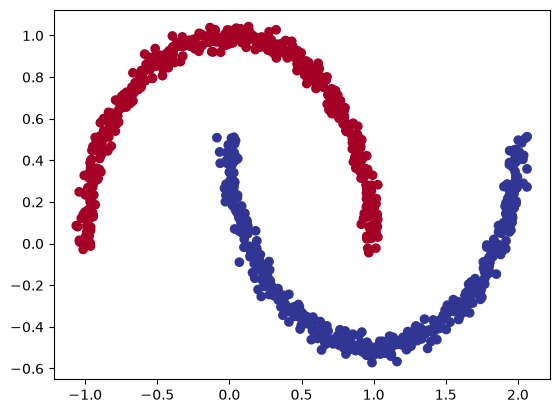

In [7]:
# Visualize with a plot
import matplotlib.pyplot as plt
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu);

In [8]:
# Check the shapes of our features and labels
X.shape, y.shape

((1000, 2), (1000,))

In [9]:
# Check how many samples we have
len(X), len(y)

(1000, 1000)

In [10]:
# View the first example of features and labels
X[0], y[0]

(array([-0.00933187,  0.39098105]), np.int64(1))

In [11]:
from tensorflow.keras import callbacks

# Set random seed
tf.random.set_seed(42)

# Create a model
model = tf.keras.Sequential([
  tf.keras.layers.Dense(32, activation="relu"), # hidden layer 1, ReLU activation
  tf.keras.layers.Dense(16, activation="relu"), # hidden layer 2, ReLU activation
  tf.keras.layers.Dense(8, activation="relu"), # hidden layer 2, ReLU activation
  tf.keras.layers.Dense(1, activation="sigmoid") # output layer, sigmoid activation
])

# Compile the model
model.compile(loss=tf.keras.losses.binary_crossentropy,
                            optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                            metrics=['accuracy'])

early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True)

# Fit the model
history = model.fit(X, y,
                        validation_split=0.2,
                        batch_size=32,   
                        callbacks=[early_stop],
                        epochs=500,
                        verbose=0)

In [12]:
model.evaluate(X, y)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 7.3829e-08


[7.382914191111922e-08, 1.0]

In [13]:
import numpy as np

def plot_decision_boundary(model, X, y):
  """
  Plots the decision boundary created by a model predicting on X.
  This function has been adapted from two phenomenal resources:
   1. CS231n - https://cs231n.github.io/neural-networks-case-study/
   2. Made with ML basics - https://github.com/GokuMohandas/MadeWithML/blob/main/notebooks/08_Neural_Networks.ipynb
  """
  # Define the axis boundaries of the plot and create a meshgrid
  x_min, x_max = X[:, 0].min() - 0.1, X[:, 0].max() + 0.1
  y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1
  xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100),
                       np.linspace(y_min, y_max, 100))

  # Create X values (we're going to predict on all of these)
  x_in = np.c_[xx.ravel(), yy.ravel()] # stack 2D arrays together: https://numpy.org/devdocs/reference/generated/numpy.c_.html

  # Make predictions using the trained model
  y_pred = model.predict(x_in)

  # Check for multi-class
  if model.output_shape[-1] > 1: # checks the final dimension of the model's output shape, if this is > (greater than) 1, it's multi-class
    print("doing multiclass classification...")
    # We have to reshape our predictions to get them ready for plotting
    y_pred = np.argmax(y_pred, axis=1).reshape(xx.shape)
  else:
    print("doing binary classifcation...")
    y_pred = np.round(np.max(y_pred, axis=1)).reshape(xx.shape)

  # Plot decision boundary
  plt.contourf(xx, yy, y_pred, cmap=plt.cm.RdYlBu, alpha=0.7)
  plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.RdYlBu)
  plt.xlim(xx.min(), xx.max())
  plt.ylim(yy.min(), yy.max())

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
doing binary classifcation...


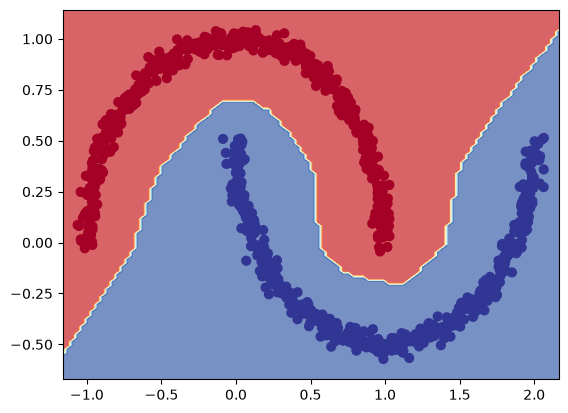

In [14]:
# View the predictions of the model with relu and sigmoid activations
plot_decision_boundary(model, X, y)

In [15]:
len(X)

1000

In [16]:
# Split data into train and test sets
X_train, y_train = X[:800], y[:800] # 80% of the data for the training set
X_test, y_test = X[800:], y[800:] # 20% of the data for the test set

# Check the shapes of the data
X_train.shape, X_test.shape # 800 examples in the training set, 200 examples in the test set

((800, 2), (200, 2))

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [18]:
# Set random seed
tf.random.set_seed(42)
# Create the model (same as model_7)
model_1 = tf.keras.Sequential([
  tf.keras.layers.Dense(32, activation="relu"), # hidden layer 1, ReLU activation
  tf.keras.layers.Dense(16, activation="relu"), # hidden layer 2, ReLU activation
  tf.keras.layers.Dense(8, activation="relu"), # hidden layer 2, ReLU activation
  tf.keras.layers.Dense(1, activation="sigmoid") # output layer, sigmoid activation
])
# Compile the model
model_1.compile(loss=tf.keras.losses.binary_crossentropy,
                            optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                            metrics=['accuracy'])

early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True)

# Fit the model
history = model_1.fit(X_train, y_train,
                        validation_split=0.2,
                        batch_size=32,   
                        callbacks=[early_stop],
                        epochs=500,
                        verbose=0)

In [19]:
loss, accuracy = model_1.evaluate(X_test, y_test)
print(f"Model loss on the test set: {loss}")
print(f"Model accuracy on the test set: {100*accuracy:.2f}%")

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 1.0000 - loss: 2.1314e-06 
Model loss on the test set: 2.1314403966243844e-06
Model accuracy on the test set: 100.00%


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
doing binary classifcation...
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
doing binary classifcation...


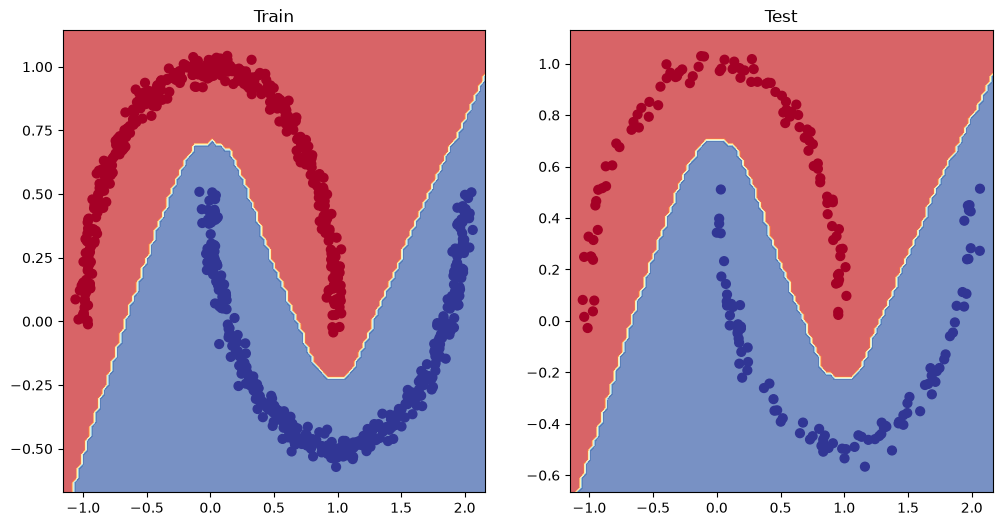

In [20]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_1, X=X_train, y=y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_1, X=X_test, y=y_test)
plt.show()

Text(0.5, 1.0, 'Model_1 training curves')

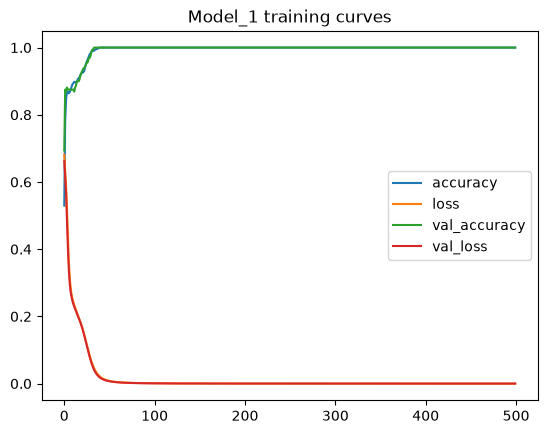

In [21]:
pd.DataFrame(history.history).plot()
plt.title("Model_1 training curves")